In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Fetal Brain Abnormality Detection Project")
print("Python image processing environment is ready!")
print("OpenCV version:", cv2.__version__)

Fetal Brain Abnormality Detection Project
Python image processing environment is ready!
OpenCV version: 5.0.0


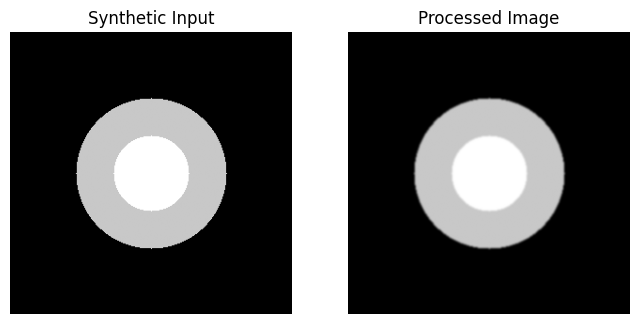

In [2]:
# Create a sample image for testing the code.
# This is synthetic data, not a real ultrasound image.

sample_image = np.zeros((300, 300), dtype=np.uint8)
cv2.circle(sample_image, (150, 150), 80, 180, -1)
cv2.circle(sample_image, (150, 150), 40, 230, -1)

# Apply image preprocessing
processed_image = cv2.GaussianBlur(
    sample_image, (5, 5), 0
)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_image, cmap="gray")
plt.title("Synthetic Input")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image, cmap="gray")
plt.title("Processed Image")
plt.axis("off")

plt.show()

In [3]:
!pip install -q ultralytics opencv-python-headless

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
All libraries imported successfully!


In [5]:
from pathlib import Path

project_dir = Path("/content/fetal-brain-project")

for folder in [
    "dataset/images/train",
    "dataset/images/val",
    "dataset/labels/train",
    "dataset/labels/val",
    "output_images"
]:
    (project_dir / folder).mkdir(
        parents=True, exist_ok=True
    )

print("Dataset folders are ready!")

Dataset folders are ready!


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

zip_files = list(drive_path.rglob("*.zip"))

for file in zip_files:
    print(file)

/content/drive/MyDrive/dataset.zip


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")
zip_files = list(drive_path.glob("*.zip"))

for i, file in enumerate(zip_files):
    print(i, file.name)

0 dataset.zip


In [10]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/YOUR_DATASET_FILENAME.zip"
)

extract_path = Path("/content/fetal-brain-project/dataset")

if not zip_path.exists():
    print("ZIP file not found. Check the filename.")
else:
    extract_path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_path)

    print("Dataset extracted successfully!")

ZIP file not found. Check the filename.


In [11]:
zip_path = Path(
    "/content/drive/MyDrive/YOUR_DATASET_FILENAME.zip"
)

In [13]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

for file in drive_path.glob("*.zip"):
    print(file.name)

Fetal_Head_Ultrasound_Dataset.zip


In [14]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for item in list(dataset_path.rglob("*"))[:50]:
    print(item.relative_to(dataset_path))

images
labels
images/train
images/val
labels/train
labels/val


In [15]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")
zip_files = list(drive_path.glob("*.zip"))

if zip_files:
    for file in zip_files:
        print("Your dataset filename:", file.name)
else:
    print("No ZIP file found in the main Google Drive folder.")

Your dataset filename: Fetal_Head_Ultrasound_Dataset.zip


In [16]:
from pathlib import Path
import zipfile

drive_path = Path("/content/drive/MyDrive")
zip_files = list(drive_path.glob("*.zip"))

if zip_files:
    zip_path = zip_files[0]
    extract_path = Path("/content/fetal-brain-project/dataset")

    extract_path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("Dataset location:", extract_path)
else:
    print("No ZIP file found. Check your Google Drive.")

Dataset extracted successfully!
Dataset location: /content/fetal-brain-project/dataset


In [17]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for item in list(dataset_path.rglob("*"))[:40]:
    print(item.relative_to(dataset_path))

test
images
labels
train
val
test/images
test/labels
images/train
images/val
labels/train
labels/val
train/images
train/labels
val/images
val/labels
val/images/076_HC.png
val/images/Patient01478_Plane3_1_of_12.png
val/images/Patient00999_Plane3_1_of_4.png
val/images/141_HC.png
val/images/Patient00959_Plane3_3_of_4.png
val/images/Patient00305_Plane3_3_of_5.png
val/images/Patient01551_Plane3_2_of_4.png
val/images/Patient01520_Plane3_2_of_2.png
val/images/459_HC.png
val/images/Patient01378_Plane3_2_of_2.png
val/images/126_HC.png
val/images/Patient00875_Plane3_2_of_3.png
val/images/703_HC.png
val/images/Patient01704_Plane3_1_of_2.png
val/images/Patient01698_Plane3_1_of_4.png
val/images/Patient01045_Plane3_4_of_5.png
val/images/Patient00835_Plane3_2_of_3.png
val/images/648_HC.png
val/images/Patient01226_Plane3_1_of_1.png
val/images/Patient01079_Plane3_3_of_3.png
val/images/303_HC.png
val/images/Patient01478_Plane3_9_of_12.png
val/images/Patient00783_Plane3_5_of_5.png
val/images/Patient01057

In [18]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

if not dataset_path.exists():
    print("Dataset folder not found. Please check extraction.")
else:
    files = list(dataset_path.rglob("*"))

    print("Total files and folders:", len(files))
    print("\nFirst 50 items:")

    for item in files[:50]:
        print(item.relative_to(dataset_path))

Total files and folders: 7679

First 50 items:
test
images
labels
train
val
test/images
test/labels
images/train
images/val
labels/train
labels/val
train/images
train/labels
val/images
val/labels
val/images/076_HC.png
val/images/Patient01478_Plane3_1_of_12.png
val/images/Patient00999_Plane3_1_of_4.png
val/images/141_HC.png
val/images/Patient00959_Plane3_3_of_4.png
val/images/Patient00305_Plane3_3_of_5.png
val/images/Patient01551_Plane3_2_of_4.png
val/images/Patient01520_Plane3_2_of_2.png
val/images/459_HC.png
val/images/Patient01378_Plane3_2_of_2.png
val/images/126_HC.png
val/images/Patient00875_Plane3_2_of_3.png
val/images/703_HC.png
val/images/Patient01704_Plane3_1_of_2.png
val/images/Patient01698_Plane3_1_of_4.png
val/images/Patient01045_Plane3_4_of_5.png
val/images/Patient00835_Plane3_2_of_3.png
val/images/648_HC.png
val/images/Patient01226_Plane3_1_of_1.png
val/images/Patient01079_Plane3_3_of_3.png
val/images/303_HC.png
val/images/Patient01478_Plane3_9_of_12.png
val/images/Patient

In [19]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
label_extensions = {".txt", ".json", ".xml"}

images = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

labels = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in label_extensions
]

print("Image files found:", len(images))
print("Annotation files found:", len(labels))

Image files found: 3832
Annotation files found: 3832


In [20]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

label_files = [
    p for p in dataset_path.rglob("*.txt")
    if p.is_file()
]

print("Text annotation files:", len(label_files))

if label_files:
    sample_file = label_files[0]

    print("\nSample annotation file:")
    print(sample_file)

    print("\nAnnotation contents:")
    print(sample_file.read_text()[:2000])
else:
    print("No TXT annotation files found.")

Text annotation files: 3832

Sample annotation file:
/content/fetal-brain-project/dataset/val/labels/Patient01760_Plane3_4_of_4.txt

Annotation contents:
0 0.269030 0.210287 0.241919 0.252648 0.212722 0.329803 0.201251 0.403933 0.203337 0.484115 0.215850 0.549168 0.244004 0.626324 0.272158 0.676248 0.316997 0.733737 0.369135 0.777610 0.424400 0.807867 0.480709 0.822995 0.544317 0.822995 0.594369 0.809380 0.639208 0.785174 0.680918 0.747352 0.723670 0.683812 0.744526 0.633888 0.758081 0.576399 0.763295 0.514372 0.757039 0.435703 0.741397 0.370651 0.715328 0.305598 0.692388 0.266263 0.650678 0.211800 0.611053 0.175492 0.559958 0.142209 0.505735 0.122542 0.468196 0.116490 0.409802 0.119516 0.366006 0.133132 0.324296 0.155825 0.286757 0.189107


In [21]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for folder in dataset_path.iterdir():
    if folder.is_dir():
        print(folder.name, "->", len(list(folder.rglob("*"))), "items")

test -> 1152 items
images -> 2 items
labels -> 2 items
train -> 5310 items
val -> 1208 items


In [24]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for folder_name in ["train", "val", "test", "images", "labels"]:
    folder = dataset_path / folder_name

    print(f"\n--- {folder_name} ---")

    if folder.exists():
        for item in list(folder.iterdir())[:10]:
            print(item.name, "(folder)" if item.is_dir() else "(file)")
    else:
        print("Folder not found")


--- train ---
images (folder)
labels (folder)

--- val ---
images (folder)
labels (folder)

--- test ---
images (folder)
labels (folder)

--- images ---
train (folder)
val (folder)

--- labels ---
train (folder)
val (folder)


In [23]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

label_files = [
    p for p in dataset_path.rglob("*.txt")
    if p.is_file()
]

print("TXT annotation files:", len(label_files))

if label_files:
    sample = label_files[0]
    print("Sample file:", sample)
    print(sample.read_text()[:1500])

TXT annotation files: 3832
Sample file: /content/fetal-brain-project/dataset/val/labels/Patient01760_Plane3_4_of_4.txt
0 0.269030 0.210287 0.241919 0.252648 0.212722 0.329803 0.201251 0.403933 0.203337 0.484115 0.215850 0.549168 0.244004 0.626324 0.272158 0.676248 0.316997 0.733737 0.369135 0.777610 0.424400 0.807867 0.480709 0.822995 0.544317 0.822995 0.594369 0.809380 0.639208 0.785174 0.680918 0.747352 0.723670 0.683812 0.744526 0.633888 0.758081 0.576399 0.763295 0.514372 0.757039 0.435703 0.741397 0.370651 0.715328 0.305598 0.692388 0.266263 0.650678 0.211800 0.611053 0.175492 0.559958 0.142209 0.505735 0.122542 0.468196 0.116490 0.409802 0.119516 0.366006 0.133132 0.324296 0.155825 0.286757 0.189107


In [25]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for file in dataset_path.rglob("*.yaml"):
    print("\nConfiguration file:", file)
    print(file.read_text()[:5000])

In [26]:
from pathlib import Path
from collections import Counter

dataset_path = Path("/content/fetal-brain-project/dataset")

class_counts = Counter()
coordinate_counts = Counter()
empty_labels = 0
invalid_lines = 0

for label_file in dataset_path.rglob("*.txt"):
    for line in label_file.read_text().splitlines():
        values = line.split()

        if not values:
            empty_labels += 1
            continue

        try:
            class_id = int(values[0])
            coordinates = [float(v) for v in values[1:]]

            if len(coordinates) < 6 or len(coordinates) % 2 != 0:
                invalid_lines += 1
                continue

            class_counts[class_id] += 1
            coordinate_counts[len(coordinates)] += 1

        except ValueError:
            invalid_lines += 1

print("Class ID counts:", dict(class_counts))
print("Coordinate counts:", dict(coordinate_counts))
print("Empty labels:", empty_labels)
print("Invalid lines:", invalid_lines)

Class ID counts: {0: 3792, 1: 1283, 2: 1476}
Coordinate counts: {66: 743, 8: 2736, 76: 142, 58: 21, 64: 1101, 68: 542, 60: 32, 80: 46, 70: 432, 84: 9, 62: 97, 72: 301, 78: 74, 74: 181, 50: 7, 10: 21, 40: 1, 82: 22, 48: 4, 38: 2, 56: 9, 54: 10, 52: 10, 42: 1, 86: 2, 46: 2, 44: 1, 12: 2}
Empty labels: 0
Invalid lines: 0


In [27]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

# 1. Find YAML configuration files
yaml_files = list(dataset_path.rglob("*.yaml")) + list(dataset_path.rglob("*.yml"))

if yaml_files:
    for file in yaml_files:
        print(f"\n--- {file} ---")
        print(file.read_text()[:4000])
else:
    print("No YAML configuration file found.")

# 2. Show the main dataset folders
print("\n--- Dataset folder structure ---")
for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        print(f"\n{folder.name}/")
        for subfolder in sorted(folder.iterdir())[:10]:
            print("  ", subfolder.name)

No YAML configuration file found.

--- Dataset folder structure ---

images/
   train
   val

labels/
   train
   val

test/
   images
   labels

train/
   images
   labels

val/
   images
   labels


In [28]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for split in ["train", "val", "test"]:
    image_dir = dataset_path / split / "images"
    label_dir = dataset_path / split / "labels"

    images = []
    if image_dir.exists():
        images = [
            p for p in image_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
        ]

    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without labels:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))
    print("Example image:", images[0].name if images else "None")
    print("Example label:", labels[0].name if labels else "None")


TRAIN
Images: 2654
Label files: 2654
Images without labels: 0
Labels without images: 0
Example image: 740_HC.png
Example label: Patient01320_Plane3_2_of_2.txt

VAL
Images: 603
Label files: 603
Images without labels: 0
Labels without images: 0
Example image: 076_HC.png
Example label: Patient01760_Plane3_4_of_4.txt

TEST
Images: 575
Label files: 575
Images without labels: 0
Labels without images: 0
Example image: Patient00895_Plane3_3_of_3.png
Example label: 587_2HC.txt


In [29]:
from pathlib import Path

dataset_path = Path("/content/fetal-brain-project/dataset")

for file in dataset_path.rglob("*"):
    if not file.is_file():
        continue

    # Skip individual annotation files
    if file.parent.name == "labels" or file.suffix.lower() == ".txt":
        continue

    if file.name.lower().startswith(
        ("readme", "data", "class", "label", "annotation", "metadata")
    ) or file.suffix.lower() in [".yaml", ".yml", ".json", ".csv", ".md"]:
        print(file)

Image: 740_HC.png
Matching label exists: True


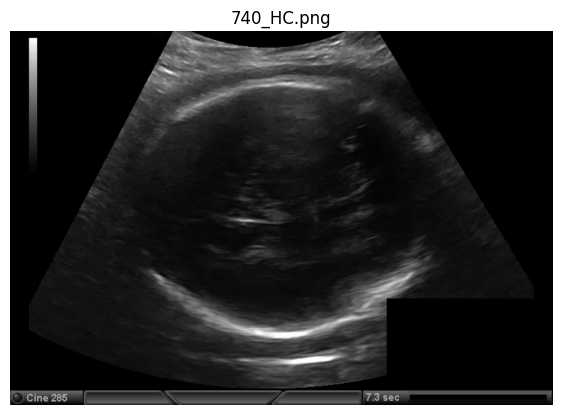


Annotation sample:
0 0.679875 0.175492 0.637122 0.146747 0.591241 0.128593 0.556830 0.122542 0.493222 0.125567 0.445255 0.140696 0.402503 0.163389 0.358707 0.198185 0.316997 0.246596 0.293014 0.282905 0.266945 0.337368 0.248175 0.397882 0.237748 0.462935 0.236705 0.521936 0.244004 0.580938 0.261731 0.641452 0.291971 0.701967 0.330553 0.750378 0.386861 0.791225 0.454640 0.813918 0.509906 0.815431 0.575600 0.798790 0.623566 0.773071 0.662148 0.742814 0.701773 0.698941 0.747654 0.623298 0.769552 0.564297 0.784150 0.493192 0.787278 0.416036 0.777894 0.347958 0.755996 0.281392 0.722628 0.222390


In [30]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset_path = Path("/content/fetal-brain-project/dataset")

image_path = next(
    p for p in (dataset_path / "train" / "images").iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
)

label_path = dataset_path / "train" / "labels" / f"{image_path.stem}.txt"

print("Image:", image_path.name)
print("Matching label exists:", label_path.exists())

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 7))
plt.imshow(image, cmap="gray")
plt.title(image_path.name)
plt.axis("off")
plt.show()

if label_path.exists():
    print("\nAnnotation sample:")
    print("\n".join(label_path.read_text().splitlines()[:3]))

In [31]:
from pathlib import Path
import yaml

project_path = Path("/content/fetal-brain-project")
dataset_path = project_path / "dataset"

config = {
    "path": str(dataset_path),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {
        0: "Brain",
        1: "CSP",
        2: "LV"
    }
}

yaml_path = project_path / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(yaml_path.read_text())

path: /content/fetal-brain-project/dataset
train: train/images
val: val/images
test: test/images
names:
  0: Brain
  1: CSP
  2: LV



In [34]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU; training may be slower.")

GPU available: False
Using CPU; training may be slower.


In [41]:
!pip -q install ultralytics